# TVOG of a maturity guarantee under LMM scenarios

This notebook calculates the time value of options and guarantees (TVOG) of savings
policies under the LIBOR market model (LMM) scenarios of
[BasicLMM](https://lifelib.io/libraries/economic/BasicLMM.html). For this example, the
`CashValue_ME_LMM` model is developed from `CashValue_ME_G2PP`, the example model of the
notebook [TVOG of a maturity guarantee under G2++ scenarios](g2pp-tvog.ipynb), which is in
turn developed from `CashValue_ME_EX4` in the **savings** library. `CashValue_ME_EX4` is the
faster version of `CashValue_ME_EX1`, which calculates the TVOG of a guaranteed minimum
accumulation benefit (GMAB) with lognormal fund returns. Like them, `CashValue_ME_LMM`
assumes no mortality, no lapses and no fees.

`CashValue_ME_LMM` takes its economic inputs from its space `ESG`, a copy of BasicLMM's
`LMM` space, which reads `lmm_input.xlsx` in the library folder. Scenario 0 is the
certainty-equivalent (CE) scenario, which follows the initial forward curve, so one run
gives both terms of the TVOG:

$$\mathrm{TVOG} = \frac{1}{N}\sum_{k=1}^{N} PV_k - PV_0$$

where $PV_k$ is the present value in scenario $k$, and $N$ the number of stochastic
scenarios.

This notebook describes the changes made to `CashValue_ME_G2PP`, and shows the model
points, the TVOG of the GMAB on the delivered input, how it depends on the bond fund and on
the tenor of the forward rates, how it compares with the G2++ scenarios, and a check
against a closed form.

## Change summary

BasicLMM's outputs have the names and shapes of BasicG2PP's, so `CashValue_ME_G2PP`'s
`Projection` space runs on the LMM scenarios unchanged. `CashValue_ME_LMM` is
`CashValue_ME_G2PP` with these changes:

* The space `ESG` is a copy of BasicLMM's `LMM` space instead of BasicG2PP's `G2PP`
  space, and the Reference `esg` of `Projection` refers to it.
* `formula_gmab_g2pp` is removed: under the LMM, the deflator and the account value are
  not lognormal, and a maturity guarantee on a fund has no closed form.
* `formula_gmab_floorlet` is new, and is described below: the closed-form GMAB cost of
  policies that mature at the second tenor date with an all-cash fund.

`CashValue_ME_G2PP`'s own changes to `CashValue_ME_EX4` stay: `scen_index` returns `ESG`'s
scenario IDs, `inv_return_table` the returns of the bond fund that `fund_id` selects in
the workbook, and `disc_factors` the deflators of every scenario; `check_pv_net_cf`
discounts with them; `result_tvog` gives the TVOG; and EX4's `scen_size`, `scen_id`,
`std_norm_rand`, `disc_rate_ann`, `disc_rate_mth` and `formula_option_put` are removed.
The run needs as many months of scenarios as the projection: `inv_return_table` raises an
error if `step_size` in the workbook is shorter than `max_proj_len`.

Click the badge below to run this notebook online on Google Colab. You need a Google account and need to be logged in to it to run this notebook on Google Colab.
[![Run on Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lifelib-dev/lifelib/blob/current/lifelib/libraries/economic/lmm-tvog.ipynb)


The next code cell below is relevant only when you run this notebook on Google Colab. It installs lifelib and creates a copy of the library for this notebook.

In [1]:
import sys, os

if 'google.colab' in sys.modules:
    lib = 'economic'; lib_dir = '/content/'+ lib
    if not os.path.exists(lib_dir):
        !pip install lifelib
        import lifelib; lifelib.create(lib, lib_dir)

    %cd $lib_dir

In [2]:
import matplotlib.pyplot as plt
import modelx as mx
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, MultipleLocator
from scipy import stats

model = mx.read_model("CashValue_ME_LMM")
proj, esg = model.Projection, model.ESG
T = 120                                   # every model point matures in month 120
n_scen = len(esg.scen_index())
print(f"{n_scen - 1:,} stochastic scenarios plus the CE scenario; fund {esg.fund_id()}, "
      f"forward rates of {esg.tenor_mth()} months")

1,000 stochastic scenarios plus the CE scenario; fund BOND_MIX, forward rates of 12 months


In [3]:
# Chart style: light-mode tokens of the reference palette, one categorical slot per fund
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
FUND_COLORS = {"CASH": "#2a78d6", "BOND_MIX": "#1baf7a", "BOND_10Y": "#eb6834"}
MODEL_COLORS = {"LMM": "#2a78d6", "G2++": "#eb6834"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titlelocation": "left", "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "legend.frameon": False,
    "legend.labelcolor": INK_2, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "figure.dpi": 110, "font.size": 9.5,
})


def percent_axis(axis, step, decimals=0):
    """Percent labels at multiples of step, without a "-0%"."""
    axis.set_major_locator(MultipleLocator(step))
    axis.set_major_formatter(FuncFormatter(
        lambda v, _: f"{0.0 if abs(v) < 1e-12 else v:.{decimals}%}"))

## Model points

All nine model points are 10-year policies: 100 policies with a sum assured of 500,000
each. Points 1, 2, 5, 6 and 9 pay a single premium. For them, the account value after the
premium, AV0, divided by the present value of the sum assured, SA · P(0, 10), shows how far
the guarantee is in the money: below 1 it pays in the CE scenario. Points 3, 4, 7 and 8
pay level premiums every month, build up account values far above the sum assured, and
their GMAB costs nothing.

In [4]:
mps = proj.model_point_table_ext()
sa = (proj.sum_assured() * proj.pols_maturity(T))[::n_scen]
av0 = proj.av_at(0, "BEF_FEE")[::n_scen]
is_single = (mps["premium_type"] == "SINGLE").to_numpy()
points = pd.DataFrame({
    "premium type": mps["premium_type"], "premium per policy": mps["premium_pp"], "SA": sa,
    "AV0": np.where(is_single, av0, np.nan),
    "AV0 / (SA P(0,10))": np.where(is_single, av0 / (sa * esg.mkt_zcb(T)), np.nan).round(3),
}, index=mps.index)
single = points.index[is_single].tolist()
points

,premium type,premium per policy,SA,AV0,"AV0 / (SA P(0,10))"
point_id,,,,,
1,SINGLE,500000,50000000.0,50000000.0,1.267
2,SINGLE,475000,50000000.0,47500000.0,1.203
3,LEVEL,450000,50000000.0,NaN,NaN
4,LEVEL,425000,50000000.0,NaN,NaN
5,SINGLE,400000,50000000.0,40000000.0,1.013
6,SINGLE,375000,50000000.0,37500000.0,0.950
7,LEVEL,350000,50000000.0,NaN,NaN
8,LEVEL,325000,50000000.0,NaN,NaN
9,SINGLE,300000,50000000.0,30000000.0,0.760


## TVOG on the delivered input

`result_tvog()` gives three present values by model point: the GMAB cost, which is the
maturity claim in excess of the account value (`pv_claims_over_av("MATURITY")`), the cost of
the guaranteed minimum death benefit (GMDB, `pv_claims_over_av("DEATH")`), and the net cash
flows (`pv_net_cf()`). For each of them, it gives the present value in the CE scenario
(`CE`), the mean over the stochastic scenarios (`mean`), their difference (`TVOG`) and the
standard error of the mean (`SE`). With antithetic variates, as in the delivered input, a
scenario and its antithetic partner are not independent, so the standard error comes from
the means of the N/2 antithetic pairs. For the GMAB cost:

In [5]:
tvog = proj.result_tvog()
tvog["GMAB"].round(0)

,CE,mean,TVOG,SE
point_id,,,,
1,0.0,4234.0,4234.0,4187.0
2,0.0,9220.0,9220.0,6226.0
3,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0
5,0.0,636311.0,636311.0,32035.0
6,1970018.0,2133823.0,163804.0,23227.0
7,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0
9,9470018.0,9463813.0,-6206.0,13515.0


The GMDB costs nothing because EX4 has no mortality. The TVOG of the present value of net
cash flows is the GMAB's TVOG with the opposite sign, plus Monte Carlo noise:

In [6]:
pd.DataFrame({"GMAB TVOG": tvog["GMAB"]["TVOG"],
              "net cash flow TVOG": tvog["net cash flow"]["TVOG"],
              "sum (noise)": tvog["GMAB"]["TVOG"] + tvog["net cash flow"]["TVOG"],
              "net cash flow SE": tvog["net cash flow"]["SE"]}).round(0)

,GMAB TVOG,net cash flow TVOG,sum (noise),net cash flow SE
point_id,,,,
1,4234.0,-4218.0,17.0,4190.0
2,9220.0,-9204.0,17.0,6227.0
3,0.0,-8423.0,-8423.0,42255.0
4,0.0,17.0,17.0,84.0
5,636311.0,-636294.0,17.0,32032.0
6,163804.0,-163788.0,17.0,23219.0
7,0.0,-6548.0,-6548.0,32846.0
8,0.0,17.0,17.0,84.0
9,-6206.0,6222.0,17.0,13546.0


## TVOG by fund, and against G2++

The ESG takes the fund from `fund_id` in the workbook. To compare funds without editing
the workbook, the next cell overrides the value of ESG's `fund_id` cell
(`esg.fund_id[()] = ...`), which recalculates everything that depends on it, and restores
the workbook's value at the end with `esg.fund_id.clear_all()`. It does the same with
`CashValue_ME_G2PP`, which runs the same policies on the G2++ scenarios of
`g2pp_input.xlsx`: the same curve, the same funds, and example parameters of a similar
shape.

In [7]:
funds = ["CASH", "BOND_MIX", "BOND_10Y"]
g2pp_model = mx.read_model("CashValue_ME_G2PP")
results = {}
for name, m in (("LMM", model), ("G2++", g2pp_model)):
    for fund in funds:
        m.ESG.fund_id[()] = fund
        results[name, fund] = m.Projection.result_tvog()["GMAB"].loc[single]
    m.ESG.fund_id.clear_all()
print(f"fund restored to {esg.fund_id()}")
for name, m in (("LMM", model), ("G2++", g2pp_model)):
    spread = np.log(m.ESG.disc_factor_paths()[1:, T]).std()
    print(f"{name:5s} standard deviation of ln D(10): {spread:.4f}")

fund restored to BOND_MIX
LMM   standard deviation of ln D(10): 0.0934
G2++  standard deviation of ln D(10): 0.1108


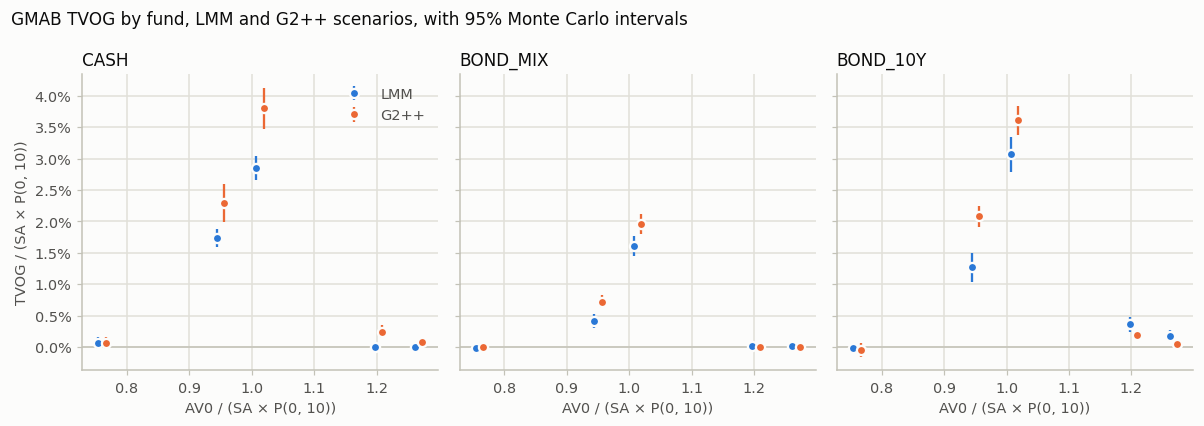

In [8]:
moneyness = points.loc[single, "AV0 / (SA P(0,10))"].to_numpy()
unit = (sa * esg.mkt_zcb(T))[[p - 1 for p in single]]     # SA P(0,10) of each point

fig, axes = plt.subplots(1, len(funds), figsize=(11, 3.9), sharex=True, sharey=True)
for ax, fund in zip(axes, funds):
    for (name, color), shift in zip(MODEL_COLORS.items(), (-0.006, 0.006)):
        gmab = results[name, fund]
        ax.errorbar(moneyness + shift, gmab["TVOG"] / unit, yerr=1.96 * gmab["SE"] / unit,
                    fmt="o", color=color, markersize=6, markeredgecolor=SURFACE,
                    markeredgewidth=1.5, elinewidth=1.5, capsize=0, zorder=3, label=name)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_title(fund)
    ax.set_xlabel("AV0 / (SA × P(0, 10))")
    percent_axis(ax.yaxis, 0.005, 1)
axes[0].set_ylabel("TVOG / (SA × P(0, 10))")
axes[0].legend(loc="upper right")
fig.suptitle("GMAB TVOG by fund, LMM and G2++ scenarios, with 95% Monte Carlo intervals",
             x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()
plt.show()

In [9]:
table = pd.concat({(fund, name): results[name, fund][["TVOG", "SE"]]
                   for fund in funds for name in MODEL_COLORS}, axis=1)
table.round(0)

CASH                               BOND_MIX                     \
                LMM                G2++                LMM               G2++   
               TVOG       SE       TVOG       SE      TVOG       SE      TVOG   
point_id                                                                        
1               0.0      0.0    30139.0  11152.0    4234.0   4187.0       0.0   
2             432.0    432.0    95945.0  19976.0    9220.0   6226.0     618.0   
5         1123644.0  38814.0  1499775.0  66074.0  636311.0  32035.0  771177.0   
6          686609.0  28564.0   903679.0  61062.0  163804.0  23227.0  285048.0   
9           24014.0  18513.0    24362.0  18318.0   -6206.0  13515.0   -2084.0   

                    BOND_10Y                               
                         LMM                G2++           
               SE       TVOG       SE       TVOG       SE  
point_id                                                   
1             0.0    71832.0  17442.0    20830.0   7190.0  
2           453.0   143076.0  24347.0    74277.0  13677.0  
5         31328.0  1211842.0  55878.0  1423709.0  46774.0  
6         21916.0   501554.0  46030.0   820980.0  32955.0  
9         10635.0    -7084.0  14528.0   -18990.0  21597.0

Near the money, at point 5, the LMM gives a lower TVOG than G2++ for every fund. With
the example inputs its deflators are less volatile: the standard deviation of ln D(10) is
0.093, against 0.111 under G2++. Away from the money the two models part in a way that one
volatility cannot explain. LMM rates are shifted lognormal: bounded below by minus the
shift, with a long upper tail. G2++ rates are Gaussian, and can fall as far as they rise.

* The guarantee of the all-cash fund pays when the bank account grows little, that is when
  rates stay low. Out of the money, at points 1 and 2, it is worth almost nothing under
  the LMM.
* The guarantee of the 10-year bond fund pays when bond prices fall, that is when rates
  rise. Out of the money it is worth more under the LMM, whose rates can rise further.
* Near the money, the mixed fund, 20% cash, 30% 5-year and 50% 10-year bonds, makes the
  guarantee cheapest under both models.

## The tenor of the forward rates

The bank account rolls over at each tenor date at the rate just set. With annual forward
rates, as in the delivered input, its return is fixed for a year at a time; a shorter
tenor makes it follow a shorter rate. The next cell runs the all-cash fund with tenors of
12, 3 and 1 months, by overriding `tenor_mth` and `fund_id`, and `step_size` to the 121
months the projection needs, which keeps the monthly tenor quick. The same volatility table
serves every tenor here; a calibrated table belongs to one tenor.

In [10]:
by_tenor = {}
esg.fund_id[()] = "CASH"
esg.step_size[()] = 121
for tenor in (12, 3, 1):
    esg.tenor_mth[()] = tenor
    by_tenor[tenor] = proj.result_tvog()["GMAB"].loc[single, ["TVOG", "SE"]]
for cells in (esg.tenor_mth, esg.step_size, esg.fund_id):
    cells.clear_all()
print(f"restored: tenor {esg.tenor_mth()} months, {esg.step_size()} months, fund {esg.fund_id()}")
pd.concat({f"tenor {t} months": df for t, df in by_tenor.items()}, axis=1).round(0)

restored: tenor 12 months, 600 months, fund BOND_MIX


tenor 12 months          tenor 3 months          tenor 1 months  \
                    TVOG       SE           TVOG       SE           TVOG   
point_id                                                                   
1                    0.0      0.0            0.0      0.0            0.0   
2                  432.0    432.0         2943.0   1383.0         3646.0   
5              1123644.0  38814.0      1207377.0  41109.0      1228928.0   
6               686609.0  28564.0       762794.0  30924.0       781844.0   
9                24014.0  18513.0        38045.0  19108.0        41277.0   

                   
               SE  
point_id           
1             0.0  
2          1642.0  
5         41573.0  
6         31429.0  
9         19248.0

A shorter tenor raises the TVOG of the all-cash fund at every point that has a value: at
point 5 by 7% with a tenor of 3 months, and by 9% with a tenor of 1 month. The bank account
then follows a shorter rate, which moves every month, and with the same volatility table
the deflators spread out more.

## A closed form at the second tenor date

Under the LMM, the deflator and the account value are not lognormal, so the GMAB of a
10-year policy has no closed form. One case has: a single-premium policy with an all-cash
fund that matures at the second tenor date $T_2$. Its account value grows with the bank
account, so at maturity it is $AV_0 (1 + \tau F_1(0))(1 + \tau F_2(T_1))$, where $\tau$ is
the tenor in years and $F_k$ the forward rate for $(T_{k-1}, T_k]$. The guarantee is then
$AV_0 / P^M(0, T_1)$ floorlets on $F_2$ with the strike $x = (SA\,P^M(0, T_1)/AV_0 - 1)/\tau$,
and Black's formula with the shift $\alpha$ gives

$$\begin{aligned}
PV &= \frac{AV_0}{P^M(0, T_1)}\,\tau P^M(0, T_2)\left[(x + \alpha)\Phi(v - d_1)
- (F_2(0) + \alpha)\Phi(-d_1)\right], \\
d_1 &= \frac{1}{v}\ln\frac{F_2(0) + \alpha}{x + \alpha} + \frac{v}{2}
\end{aligned}$$

where $v$ is the caplet volatility of $F_2$, `esg.caplet_vol(2)`, times $\sqrt{T_1}$.
`formula_gmab_floorlet(t)` gives this value for the single-premium model points maturing
at month `t`. The next cell makes the policies 2-year ones, by assigning a copy of the
model point table with `policy_term` 2, selects the all-cash fund, and compares the Monte
Carlo results with the formula. It restores the table and the fund at the end.

In [11]:
proj.model_point_table = proj.model_point_moneyness.assign(policy_term=2)
esg.fund_id[()] = "CASH"
gmab = proj.result_tvog()["GMAB"].loc[single]
formula = proj.formula_gmab_floorlet(24)
check = pd.DataFrame({"CE": gmab["CE"], "mean": gmab["mean"], "SE": gmab["SE"],
                      "closed form": formula})
check["z"] = np.where(check["SE"] > 0, (check["mean"] - check["closed form"])
                      / check["SE"].where(check["SE"] > 0, 1.0), 0.0)
proj.model_point_table = proj.model_point_moneyness
esg.fund_id.clear_all()
check.round(2)

,CE,mean,SE,closed form,z
point_id,,,,,
1,0.00,0.00,0.00,0.00,0.00
2,0.00,79766.54,3397.26,80189.20,-0.12
5,7414775.28,7414251.43,1542.03,7414775.28,-0.34
6,9914775.28,9914251.43,1542.03,9914775.28,-0.34
9,17414775.28,17414251.43,1542.03,17414775.28,-0.34


The Monte Carlo means are within half a standard error of the closed form. Point 1 is out
of reach: its account value at maturity always exceeds the sum assured, because rates
cannot fall below minus the shift, so both values are 0. Points 5, 6 and 9 are deep in the
money, and their guarantee pays in every scenario. Each is then worth SA times the
deflator less AV0, so all three have the same Monte Carlo error.

The library's test suite checks these results more tightly: in every scenario the GMAB
cost equals D(T) · (SA − AV0 · fund growth)⁺ recomputed from the ESG paths, to 1e-10 of
the sum assured, and the closed form holds with 4,000 scenarios for tenors of 12 and 6
months (`tests/test_cashvalue_me_lmm.py`).